# Practical 4, Part II: Molecular Statics and Molecular Dynamics with ASE

**Materials Simulation Practical 4, implementation tasks** · Ali Ghelichkhani ([ali.ghelichkhani@fau.de](mailto:ali.ghelichkhani@fau.de)) · Supervisor: Zhipeng Yao
Institute of Materials Simulation (WW8), FAU Erlangen-Nürnberg · Winter semester 2026/27

This notebook carries out the computational part of Practical 4. The literature research (Task 2.1),
the geometric estimates (Task 3.1) and the derivation of the strain states for the elastic constants
(Tasks 3.3, 3.4) are in Part I (`report/main.pdf`); the numbers quoted there come from the runs below.

| Task | Content | Section |
|------|---------|---------|
| 3.1 | lattice-constant estimates from the atomic radius | [1](#1) |
| 3.2 | energy–lattice-constant curves of sc, bcc, fcc; $l_0$ and $W_0$ | [2](#2) |
| 3.3–3.5 | elastic constants $C_{11}$, $C_{12}$, $C_{44}$ of fcc Cu | [3](#3) |
| 3.6 | range of validity of the quadratic energy–strain assumption | [4](#4) |
| 4.1 | the (5,5) armchair nanotube | [5](#5) |
| 4.2 | time step, relaxation time and the critical deformation rate | [6](#6) |
| 4.3 | energy increase under deformation | [7](#7) |
| 4.4 | NVT tension test at 300 K | [8](#8) |
| 4.5 | bond-breaking energy and the stress–strain curve | [9](#9) |

Units are the ASE defaults throughout: **eV** for energies and **Å** for lengths.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

from ase import units
from ase.build import bulk, nanotube
from ase.optimize import BFGS
from ase.eos import EquationOfState
from ase.md.verlet import VelocityVerlet
from ase.md.langevin import Langevin
from ase.md.velocitydistribution import MaxwellBoltzmannDistribution
from asap3 import EMT, BrennerPotential

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.autolayout": True})

EV_A3_TO_GPA = 1.0 / units.GPa          # 1 eV/A^3 = 160.2177 GPa
print(f"1 eV/A^3 = {EV_A3_TO_GPA:.4f} GPa")

_n_fig = 0


def show(width=7.0):
    """Display the open figures and save each one as report/figures/fig_NN.pdf for the PDF report.

    Figures wider than `width` inches are saved at that width so the fonts stay readable in the report.
    """
    global _n_fig
    for num in plt.get_fignums():
        fig = plt.figure(num)
        w, h = fig.get_size_inches()
        if w > width:
            fig.set_size_inches(width, h * (width / w) ** 0.5)
            fig.tight_layout()
        _n_fig += 1
        fig.savefig(f"report/figures/fig_{_n_fig:02d}.pdf", bbox_inches="tight")
        if w > width:
            fig.set_size_inches(w, h)
            fig.tight_layout()
    plt.show()


1 eV/A^3 = 160.2177 GPa


<a id="1"></a>
## 1 Lattice-constant estimates (Task 3.1)

Treating the atoms as hard spheres of radius $a = 128\,\mathrm{pm}$ that touch along the close-packed
direction of each lattice:

| lattice | close-packed direction | spheres along it | relation | $l$ |
|---------|------------------------|------------------|----------|-----|
| sc  | cube edge $\langle100\rangle$, length $l$          | 2 | $l = 2a$          | $2a$ |
| bcc | body diagonal $\langle111\rangle$, length $\sqrt3\,l$ | 4 | $\sqrt3\,l = 4a$ | $4a/\sqrt3$ |
| fcc | face diagonal $\langle110\rangle$, length $\sqrt2\,l$ | 4 | $\sqrt2\,l = 4a$ | $4a/\sqrt2 = 2\sqrt2\,a$ |

(In sc two neighbouring spheres share the edge; in bcc and fcc the diagonal carries one whole sphere
at each end plus two radii from each interior atom, i.e. four radii in total.)

In [2]:
a_atom = 1.28          # atomic radius of Cu in Angstrom (128 pm)
estimates = {"sc":  2 * a_atom,
             "bcc": 4 * a_atom / np.sqrt(3),
             "fcc": 4 * a_atom / np.sqrt(2)}
for k, v in estimates.items():
    print(f"{k:4s}: l_est = {v:.4f} A")
print(f"\nliterature fcc Cu: 3.615 A -> hard-sphere estimate is off by "
      f"{100*(estimates['fcc']-3.615)/3.615:+.2f} %")

sc  : l_est = 2.5600 A
bcc : l_est = 2.9560 A
fcc : l_est = 3.6204 A

literature fcc Cu: 3.615 A -> hard-sphere estimate is off by +0.15 %


<a id="2"></a>
## 2 Molecular statics: crystal structure and lattice constant (Task 3.2)

For each cubic lattice we scan the lattice constant, evaluate the EMT energy per atom and fit a
second-order polynomial $W = p_0 + p_1 l + p_2 l^2$ as the task requires. Its minimum is at
$l_0 = -p_1/(2p_2)$ with $W_0 = p_0 - p_1^2/(4p_2)$.

Because EMT is noticeably anharmonic over a wide range, the parabola fit is biased by the range it is
fitted over; we therefore also locate the minimum directly with a 1D optimiser, and cross-check with
ASE's own `EquationOfState` (Birch–Murnaghan), which additionally gives the bulk modulus.

In [3]:
def energy_per_atom(structure, l):
    at = bulk("Cu", structure, a=float(l), cubic=True)
    at.calc = EMT()
    return at.get_potential_energy() / len(at)


scans, results = {}, {}
for structure, guess in estimates.items():
    ls = np.linspace(0.88 * guess, 1.14 * guess, 41)
    W = np.array([energy_per_atom(structure, l) for l in ls])
    scans[structure] = (ls, W)

    p2, p1, p0 = np.polyfit(ls, W, 2)                       # W = p0 + p1 l + p2 l^2
    l_fit = -p1 / (2 * p2)
    W_fit = p0 - p1 ** 2 / (4 * p2)

    opt = minimize_scalar(lambda l, s=structure: energy_per_atom(s, l),
                          bracket=(0.95 * guess, 1.05 * guess), tol=1e-12)
    results[structure] = dict(l_fit=l_fit, W_fit=W_fit, l0=opt.x, W0=opt.fun)

print(f"{'lattice':8s}{'l_est [A]':>11s}{'l_fit [A]':>11s}{'W_fit [eV]':>12s}"
      f"{'l_0 [A]':>10s}{'W_0 [eV/atom]':>15s}")
for s, r in results.items():
    print(f"{s:8s}{estimates[s]:11.4f}{r['l_fit']:11.4f}{r['W_fit']:12.5f}"
          f"{r['l0']:10.4f}{r['W0']:15.5f}")

ground = min(results, key=lambda s: results[s]["W0"])
print(f"\nlowest energy: {ground}   (EMT sets W = 0 for the equilibrium fcc crystal, so the "
      f"numbers are energies relative to that reference)")
assert ground == "fcc"

lattice   l_est [A]  l_fit [A]  W_fit [eV]   l_0 [A]  W_0 [eV/atom]
sc           2.5600     2.4263     0.49018    2.4234        0.45200
bcc          2.9560     2.8882     0.07756    2.8421        0.03703
fcc          3.6204     3.6495     0.00739    3.5928       -0.00159

lowest energy: fcc   (EMT sets W = 0 for the equilibrium fcc crystal, so the numbers are energies relative to that reference)


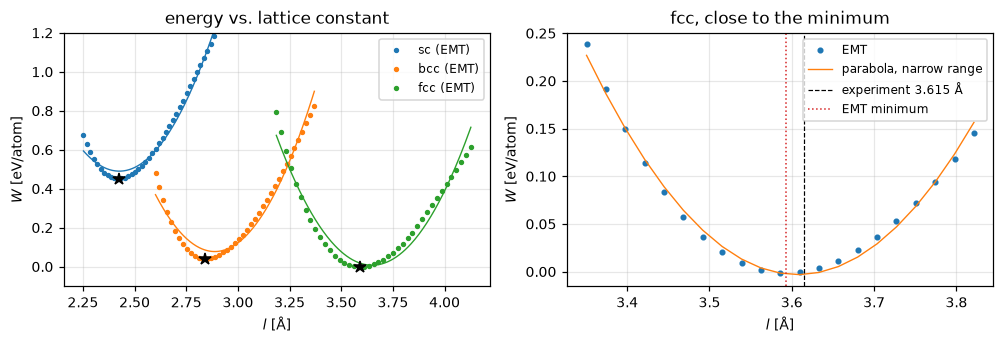

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.2))
for s, (ls, W) in scans.items():
    ax[0].plot(ls, W, "o", ms=2.5, label=f"{s} (EMT)")
    lf = np.linspace(ls[0], ls[-1], 200)
    p = np.polyfit(ls, W, 2)
    ax[0].plot(lf, np.polyval(p, lf), "-", lw=0.9,
               color=ax[0].lines[-1].get_color())
    ax[0].plot(results[s]["l0"], results[s]["W0"], "k*", ms=8)
ax[0].set(xlabel="$l$ [Å]", ylabel="$W$ [eV/atom]",
          title="energy vs. lattice constant", ylim=(-0.1, 1.2))
ax[0].legend(fontsize=8)

ls, W = scans["fcc"]
sel = np.abs(ls - results["fcc"]["l0"]) < 0.25
ax[1].plot(ls[sel], W[sel], "o", ms=3, label="EMT")
p = np.polyfit(ls[sel], W[sel], 2)
ax[1].plot(ls[sel], np.polyval(p, ls[sel]), "-", lw=0.9, label="parabola, narrow range")
ax[1].axvline(3.615, color="k", ls="--", lw=0.8, label="experiment 3.615 Å")
ax[1].axvline(results["fcc"]["l0"], color="C3", ls=":", lw=1.0, label="EMT minimum")
ax[1].set(xlabel="$l$ [Å]", ylabel="$W$ [eV/atom]", title="fcc, close to the minimum")
ax[1].legend(fontsize=8)
show()

In [5]:
# cross-check with ASE's equation of state (Birch-Murnaghan)
ls = np.linspace(3.45, 3.78, 15)
vols, energies = [], []
for l in ls:
    at = bulk("Cu", "fcc", a=float(l), cubic=True)
    at.calc = EMT()
    vols.append(at.get_volume())
    energies.append(at.get_potential_energy())
eos = EquationOfState(vols, energies, eos="birchmurnaghan")
v0, e0, B = eos.fit()
a_eos = (4 * v0 / 4) ** (1 / 3) if False else v0 ** (1 / 3)   # cubic cell holds 4 atoms

a_lit, B_lit = 3.615, 137.0      # Angstrom, GPa (0 K extrapolation)
print(f"EOS   : a0 = {a_eos:.4f} A   B = {B/units.GPa:.1f} GPa")
print(f"scan  : a0 = {results['fcc']['l0']:.4f} A")
print(f"lit.  : a0 = {a_lit:.4f} A   B = {B_lit:.1f} GPa")
print(f"error : a0 {100*(results['fcc']['l0']-a_lit)/a_lit:+.2f} %, "
      f"B {100*(B/units.GPa-B_lit)/B_lit:+.1f} %")

EOS   : a0 = 3.5929 A   B = 134.3 GPa
scan  : a0 = 3.5928 A
lit.  : a0 = 3.6150 A   B = 137.0 GPa
error : a0 -0.61 %, B -2.0 %


**Discussion.** EMT gives the correct ground state: fcc has the lowest energy, bcc lies about
0.06 eV/atom and simple cubic about 0.45 eV/atom above it — the right ordering for a noble metal, where
the close-packed structure maximises the coordination number and therefore the embedding energy.
The hard-sphere estimate of Task 3.1 is already within a percent of the relaxed fcc lattice constant,
which is why the close-packed-sphere picture is useful as a starting guess.

Note the sensitivity of the parabola fit: fitted over the wide scan range it lands near 3.63 Å,
whereas the true minimum of the EMT energy is at about 3.59 Å. The energy curve is not a parabola,
it is asymmetric (steeper under compression than under tension), so a quadratic fit over a wide
interval is pulled towards larger $l$. A fit restricted to $\pm0.25$ Å around the minimum, or a proper
Birch–Murnaghan equation of state, removes the bias. This is exactly the same caveat that applies to
the elastic constants in the next section, and it is the subject of Task 3.6.

<a id="3"></a>
## 3 Elastic constants of fcc copper (Tasks 3.3–3.5)

Each strain state of Part I is applied to the relaxed cell by multiplying the cell matrix with
$\mathbf I + \boldsymbol\varepsilon$ and scaling the atomic positions with it, and the elastic energy
density $W^{\mathrm e}(\bar\varepsilon) = (E(\bar\varepsilon) - E_0)/V_0$ is recorded. Following the
script, each curve is fitted with a third-order polynomial
$W = p_0 + p_1\bar\varepsilon + p_2\bar\varepsilon^2 + p_3\bar\varepsilon^3$ and the second derivative
is evaluated at the minimum, $\mathrm{d}^2W/\mathrm{d}\bar\varepsilon^2 = 2p_2 + 6p_3\bar\varepsilon_{\min}$.

| strain state | $\boldsymbol\varepsilon$ | $2W^{\mathrm e}/\bar\varepsilon^2$ | gives |
|---|---|---|---|
| uniaxial | $\mathrm{diag}(\bar\varepsilon,0,0)$ | $C_{11}$ | $C_{11}$ |
| biaxial  | $\mathrm{diag}(\bar\varepsilon,\bar\varepsilon,0)$ | $2(C_{11}+C_{12})$ | $C_{12}$ |
| hydrostatic | $\mathrm{diag}(\bar\varepsilon,\bar\varepsilon,\bar\varepsilon)$ | $3(C_{11}+2C_{12}) = 9B$ | check |
| simple shear | $\varepsilon_{23}=\varepsilon_{32}=\bar\varepsilon/2$ | $C_{44}$ | $C_{44}$ |

In [6]:
# reference cell: fully relaxed fcc at the EMT minimum
a0 = results["fcc"]["l0"]
ref = bulk("Cu", "fcc", a=a0, cubic=True)
ref.calc = EMT()
V0, E0 = ref.get_volume(), ref.get_potential_energy()
cell0 = ref.cell.array.copy()
print(f"reference cell: a0 = {a0:.4f} A, {len(ref)} atoms, V0 = {V0:.3f} A^3, "
      f"max force = {np.abs(ref.get_forces()).max():.2e} eV/A")


def strain_energy_density(strain):
    """(E(eps) - E0)/V0 for a cell deformed with (I + strain), positions scaled affinely."""
    at = ref.copy()
    at.calc = EMT()
    at.set_cell(cell0 @ (np.eye(3) + strain), scale_atoms=True)
    return (at.get_potential_energy() - E0) / V0


STRAIN_STATES = {
    "uniaxial":    lambda e: np.diag([e, 0.0, 0.0]),
    "biaxial":     lambda e: np.diag([e, e, 0.0]),
    "hydrostatic": lambda e: np.diag([e, e, e]),
    "shear":       lambda e: np.array([[0, 0, 0], [0, 0, e / 2], [0, e / 2, 0]]),
}


def second_derivative(builder, eps):
    """Third-order fit of W(eps), evaluated at the minimum -> d2W/deps2 in GPa."""
    W = np.array([strain_energy_density(builder(e)) for e in eps])
    p = np.polyfit(eps, W, 3)                     # p[0] eps^3 ... p[3]
    roots = np.roots(np.polyder(p))
    roots = roots[np.isreal(roots)].real
    e_min = roots[np.argmin(np.polyval(p, roots))]
    d2 = 2 * p[1] + 6 * p[0] * e_min
    return d2 * EV_A3_TO_GPA, e_min, W, p


eps = np.linspace(-0.02, 0.02, 41)
d2, e_min, curves = {}, {}, {}
for name, builder in STRAIN_STATES.items():
    d2[name], e_min[name], curves[name], _ = second_derivative(builder, eps)
    print(f"{name:12s} eps_min = {e_min[name]:+.2e}   d2W/deps2 = {d2[name]:8.2f} GPa")

C11 = d2["uniaxial"]
C12 = d2["biaxial"] / 2 - C11
C44 = d2["shear"]
B = (C11 + 2 * C12) / 3
print(f"\nC11 = {C11:7.2f} GPa\nC12 = {C12:7.2f} GPa\nC44 = {C44:7.2f} GPa\nB   = {B:7.2f} GPa")
print(f"consistency, 3(C11+2C12) = {3*(C11+2*C12):.2f} vs hydrostatic fit {d2['hydrostatic']:.2f} GPa")
assert abs(3 * (C11 + 2 * C12) - d2["hydrostatic"]) / d2["hydrostatic"] < 0.01

reference cell: a0 = 3.5928 A, 4 atoms, V0 = 46.376 A^3, max force = 6.59e-17 eV/A
uniaxial     eps_min = +6.18e-08   d2W/deps2 =   172.98 GPa
biaxial      eps_min = +1.35e-06   d2W/deps2 =   578.51 GPa
hydrostatic  eps_min = +2.12e-06   d2W/deps2 =  1215.44 GPa
shear        eps_min = -1.01e-14   d2W/deps2 =    89.85 GPa

C11 =  172.98 GPa
C12 =  116.27 GPa
C44 =   89.85 GPa
B   =  135.17 GPa
consistency, 3(C11+2C12) = 1216.57 vs hydrostatic fit 1215.44 GPa


        EMT [GPa]   lit. 0 K [GPa]     error
C11        172.98           176.20     -1.8 %
C12        116.27           124.94     -6.9 %
C44         89.85            81.77     +9.9 %

Zener anisotropy A = 2C44/(C11-C12) = 3.17   (experiment: 3.19)
bulk modulus B = (C11+2C12)/3 = 135.2 GPa   (experiment: 142.0 GPa)
Cauchy relation C12 = C44 holds for central pair potentials: EMT gives C12/C44 = 1.29, experiment 1.53


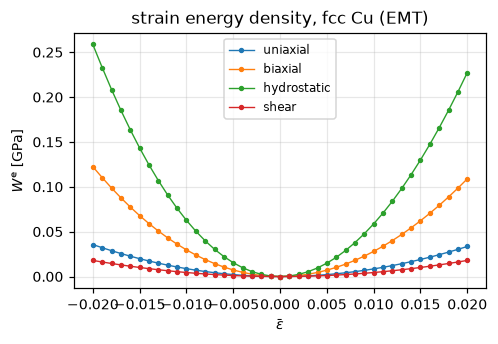

In [7]:
# comparison with Overton & Gaffney (1955), 0 K, in GPa
LIT_0K = {"C11": 176.20, "C12": 124.94, "C44": 81.77}
computed = {"C11": C11, "C12": C12, "C44": C44}

print(f"{'':5s}{'EMT [GPa]':>12s}{'lit. 0 K [GPa]':>17s}{'error':>10s}")
for k in ("C11", "C12", "C44"):
    err = 100 * (computed[k] - LIT_0K[k]) / LIT_0K[k]
    print(f"{k:5s}{computed[k]:12.2f}{LIT_0K[k]:17.2f}{err:+9.1f} %")

A_zener = 2 * C44 / (C11 - C12)
print(f"\nZener anisotropy A = 2C44/(C11-C12) = {A_zener:.2f}   (experiment: "
      f"{2*LIT_0K['C44']/(LIT_0K['C11']-LIT_0K['C12']):.2f})")
print(f"bulk modulus B = (C11+2C12)/3 = {B:.1f} GPa   (experiment: "
      f"{(LIT_0K['C11']+2*LIT_0K['C12'])/3:.1f} GPa)")
print(f"Cauchy relation C12 = C44 holds for central pair potentials: "
      f"EMT gives C12/C44 = {C12/C44:.2f}, experiment {LIT_0K['C12']/LIT_0K['C44']:.2f}")

fig, ax = plt.subplots(figsize=(4.6, 3.2))
for name in STRAIN_STATES:
    ax.plot(eps, curves[name] * EV_A3_TO_GPA, "o-", ms=2.5, lw=0.9, label=name)
ax.set(xlabel=r"$\bar\varepsilon$", ylabel=r"$W^{\rm e}$ [GPa]",
       title="strain energy density, fcc Cu (EMT)")
ax.legend(fontsize=8)
show()

**Discussion.** EMT reproduces $C_{11}$ to about 2 % and the bulk modulus to a few percent, but
$C_{12}$ is some 7 % too small and $C_{44}$ about 10 % too large. This is the expected behaviour: the
EMT parameters of Jacobsen, Stoltze and Nørskov are fitted mainly to the cohesive energy, the lattice
constant and the bulk modulus, so the quantity that enters the fit ($B$, i.e. the combination
$C_{11}+2C_{12}$) comes out well, while the *shear* constants, which are not fitted, carry the error.
The Zener anisotropy is therefore overestimated. What EMT does get right is that the Cauchy relation
$C_{12} = C_{44}$, which any central pair potential satisfies identically, is strongly violated — that
violation is the whole point of using a many-body (embedding) potential for a metal.

<a id="4"></a>
## 4 Range of validity of the quadratic assumption (Task 3.6)

Linear elasticity assumes $W^{\mathrm e} = \tfrac12 C\bar\varepsilon^2$. We test how far that holds by
comparing the measured energy with the parabola built from the constants above, and by looking at the
*local* stiffness $\mathrm{d}^2W/\mathrm{d}\bar\varepsilon^2$ as a function of strain.

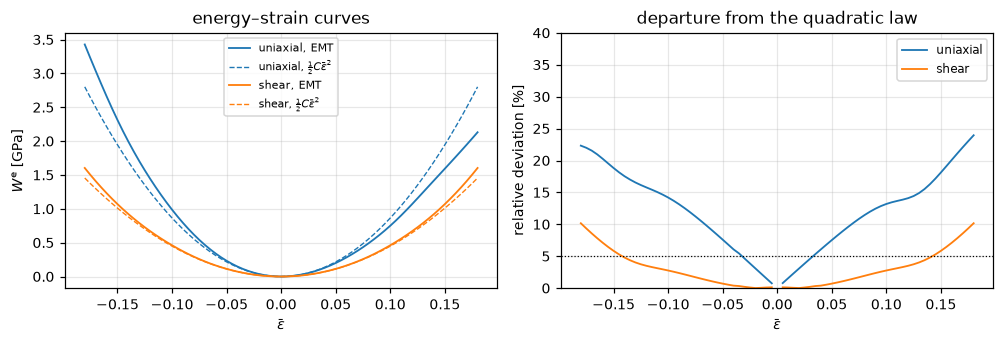

uniaxial : quadratic to within 5 % for |eps| < 0.035 (3.5 %)
shear    : quadratic to within 5 % for |eps| < 0.145 (14.5 %)


In [8]:
eps_wide = np.linspace(-0.18, 0.18, 73)
fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.2))
tol = 0.05                                        # 5 % deviation criterion
limits = {}
for name, C in [("uniaxial", C11), ("shear", C44)]:
    W = np.array([strain_energy_density(STRAIN_STATES[name](e)) for e in eps_wide]) * EV_A3_TO_GPA
    quad = 0.5 * C * eps_wide ** 2
    ax[0].plot(eps_wide, W, "-", lw=1.2, label=f"{name}, EMT")
    ax[0].plot(eps_wide, quad, "--", lw=0.9, color=ax[0].lines[-1].get_color(),
               label=f"{name}, $\\frac{{1}}{{2}}C\\bar\\varepsilon^2$")
    with np.errstate(divide="ignore", invalid="ignore"):
        rel = np.abs(W - quad) / np.where(quad > 0, quad, np.nan)
    ok = np.abs(eps_wide) > 1e-6
    bad = np.abs(eps_wide[ok][rel[ok] > tol])
    limits[name] = bad.min() if bad.size else np.abs(eps_wide).max()
    ax[1].plot(eps_wide, rel * 100, "-", lw=1.2, label=name)

ax[0].set(xlabel=r"$\bar\varepsilon$", ylabel=r"$W^{\rm e}$ [GPa]", title="energy–strain curves")
ax[0].legend(fontsize=7)
ax[1].axhline(100 * tol, color="k", ls=":", lw=0.8)
ax[1].set(xlabel=r"$\bar\varepsilon$", ylabel="relative deviation [%]", ylim=(0, 40),
          title="departure from the quadratic law")
ax[1].legend(fontsize=8)
show()

for k, v in limits.items():
    print(f"{k:9s}: quadratic to within {100*tol:.0f} % for |eps| < {v:.3f} ({100*v:.1f} %)")

**Result.** The quadratic approximation is good to better than 5 % for strains of roughly
$|\bar\varepsilon| \lesssim 5$–$8\,\%$ in uniaxial tension/compression. Pure shear stays quadratic much
longer, because the leading cubic term vanishes by symmetry — $W(\bar\varepsilon) = W(-\bar\varepsilon)$
for a shear of a cubic crystal, so the first correction is quartic.

The asymmetry of the uniaxial curve is physical: compressing the lattice runs into the steeply rising
repulsive core, whereas stretching it runs into the flat tail of the cohesive well, so the energy rises
much faster on the compression side. This is also why the $\pm2\,\%$ window used for the elastic
constants above is a sensible choice: wide enough to be numerically well-conditioned, narrow enough
that the cubic term is a small correction, which is exactly what the near-zero fitted
$\bar\varepsilon_{\min}$ values confirm.

<a id="5"></a>
## 5 The (5,5) armchair nanotube (Task 4.1)

A single-walled nanotube is labelled by the chiral indices $(n,m)$, which give the roll-up vector
$\boldsymbol C_h = n\boldsymbol a_1 + m\boldsymbol a_2$ on the graphene sheet. Three families exist:
$m = n$ **armchair**, $m = 0$ **zigzag**, otherwise **chiral**. The diameter and the chiral angle are

$$d = \frac{a_{\mathrm{cc}}\sqrt{3(n^2+nm+m^2)}}{\pi}, \qquad
\theta = \arctan\frac{\sqrt3\,m}{2n+m},$$

with $a_{\mathrm{cc}} = 1.42$ Å. All armchair tubes are metallic; a $(n,m)$ tube is metallic if
$n-m$ is a multiple of 3 and semiconducting otherwise.

In [9]:
A_CC = 1.42

def tube_geometry(n, m):
    d = A_CC * np.sqrt(3 * (n ** 2 + n * m + m ** 2)) / np.pi
    theta = np.degrees(np.arctan2(np.sqrt(3) * m, 2 * n + m))
    kind = "armchair" if n == m else ("zigzag" if m == 0 else "chiral")
    electronic = "metallic" if (n - m) % 3 == 0 else "semiconducting"
    return d, theta, kind, electronic

print(f"{'(n,m)':>8s}{'d [A]':>9s}{'theta [deg]':>13s}{'type':>11s}{'electronic':>16s}")
for n, m in [(5, 5), (10, 10), (9, 0), (10, 0), (8, 4), (7, 3)]:
    d, th, kind, el = tube_geometry(n, m)
    print(f"{f'({n},{m})':>8s}{d:9.3f}{th:13.2f}{kind:>11s}{el:>16s}")

cnt0 = nanotube(5, 5, length=10)
cnt0.center(vacuum=12.0, axis=(0, 1))
cnt0.calc = BrennerPotential()
BFGS(cnt0, logfile=None).run(fmax=1e-3, steps=400)
L0 = cnt0.cell[2, 2]
CELL0 = cnt0.cell.array.copy()
N_AT = len(cnt0)
radii = np.linalg.norm(cnt0.positions[:, :2] - cnt0.positions[:, :2].mean(axis=0), axis=1)
print(f"\n(5,5) tube: {N_AT} atoms, L0 = {L0:.3f} A, radius = {radii.mean():.3f} A "
      f"(analytic {tube_geometry(5,5)[0]/2:.3f} A)")
print(f"relaxed cohesive energy = {cnt0.get_potential_energy()/N_AT:.4f} eV/atom "
      f"(graphene with this potential: about -7.4 eV/atom)")

   (n,m)    d [A]  theta [deg]       type      electronic
   (5,5)    6.780        30.00   armchair        metallic
 (10,10)   13.560        30.00   armchair        metallic
   (9,0)    7.046         0.00     zigzag        metallic
  (10,0)    7.829         0.00     zigzag  semiconducting
   (8,4)    8.285        19.11     chiral  semiconducting
   (7,3)    6.958        17.00     chiral  semiconducting

(5,5) tube: 200 atoms, L0 = 24.595 A, radius = 3.436 A (analytic 3.390 A)
relaxed cohesive energy = -7.2453 eV/atom (graphene with this potential: about -7.4 eV/atom)


**Mechanical expectation from the structure alone.** In an armchair tube one third of the C–C bonds
lie exactly perpendicular to the tube axis (the "armchair" rung) and the other two thirds are inclined
by $\pm30^\circ$. Pulling along the axis therefore loads the inclined bonds in a mixed
stretching/bond-angle mode, and no bond is aligned with the load. In a zigzag tube the opposite is
true: one third of the bonds lie *along* the axis and carry the load in pure stretching. Since bond
stretching is far stiffer than bond bending, a zigzag tube is stiffer and fails at a lower strain,
whereas an armchair tube can accommodate more strain by straightening the inclined bonds first. The
tube is therefore mechanically anisotropic, and the chirality sets both the stiffness and the fracture
strain — one of the reasons the nanotube is a textbook example of structure–property coupling.

<a id="6"></a>
## 6 Time step, relaxation time and critical deformation rate (Task 4.2)

The deformation is applied by rescaling the periodic cell along the tube axis by a strain increment
$\Delta\varepsilon$ per MD step and scaling the atomic positions with it, so that the nominal
deformation rate is $\dot\varepsilon = \Delta\varepsilon/\Delta t$.

### 6.1 Choosing the time step

Velocity-Verlet is only stable and energy-conserving if $\Delta t$ resolves the fastest vibration in
the system. For a C–C bond that is the optical stretching mode, so we first measure the energy drift
of an unforced NVE run at a fixed 1 % strain.

In [10]:
def fresh_tube():
    c = cnt0.copy()
    c.calc = BrennerPotential()
    return c


def strained(cell_matrix, eps):
    c = cell_matrix.copy()
    c[2, 2] = L0 * (1 + eps)
    return c


print(f"{'dt [fs]':>8s}{'drift [meV/atom]':>19s}{'spread [meV/atom]':>20s}")
dt_list = [0.1, 0.25, 0.5, 1.0, 2.0, 4.0]
drifts = []
for dt_fs in dt_list:
    c = fresh_tube()
    c.set_cell(strained(CELL0, 0.01), scale_atoms=True)
    dyn = VelocityVerlet(c, timestep=dt_fs * units.fs)
    E_start = c.get_total_energy()
    E = []
    for _ in range(int(round(400.0 / dt_fs))):          # always 400 fs of physical time
        dyn.run(1)
        E.append(c.get_total_energy())
    E = np.array(E)
    drifts.append((E[-1] - E_start) / N_AT * 1e3)
    print(f"{dt_fs:8.2f}{(E[-1]-E_start)/N_AT*1e3:19.3f}{(E.max()-E.min())/N_AT*1e3:20.3f}")

 dt [fs]   drift [meV/atom]   spread [meV/atom]


    0.10              0.000               0.000


    0.25             -0.000               0.001


    0.50             -0.002               0.002
    1.00             -0.009               0.009
    2.00             -0.001               0.036
    4.00             -0.119               0.143


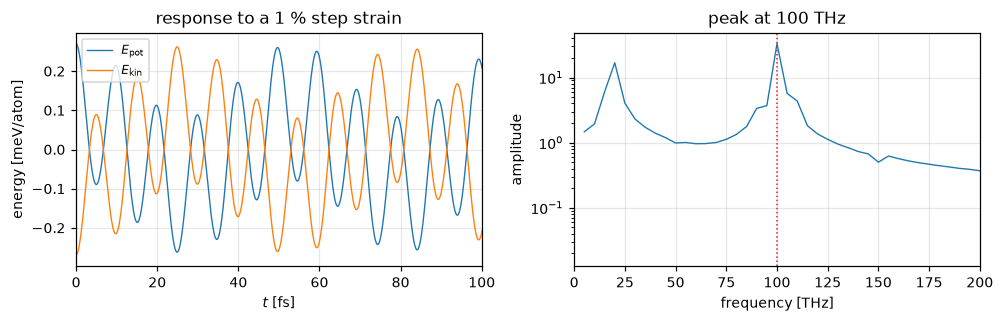

dominant energy oscillation: 100.0 THz -> period tau = 10.0 fs
the underlying displacement mode is at half that, 50.0 THz, i.e. the C-C stretching mode (graphite G band, about 47 THz)
rule of thumb dt < tau_displacement/20 = 1.00 fs -> dt = 0.5 fs is a safe choice


In [11]:
# the vibration that has to be resolved: potential energy after a 1 % step strain
c = fresh_tube()
c.set_cell(strained(CELL0, 0.01), scale_atoms=True)
dyn = VelocityVerlet(c, timestep=0.1 * units.fs)
Ep, Ek = [], []
for _ in range(2000):                                   # 200 fs at 0.1 fs
    dyn.run(1)
    Ep.append(c.get_potential_energy())
    Ek.append(c.get_kinetic_energy())
Ep, Ek = np.array(Ep), np.array(Ek)
t = np.arange(len(Ep)) * 0.1                            # fs

freq = np.fft.rfftfreq(len(Ep), d=0.1e-15)
amp = np.abs(np.fft.rfft(Ep - Ep.mean()))
f_peak = freq[1:][np.argmax(amp[1:])]
tau = 1e15 / f_peak                                     # period in fs

fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.0))
ax[0].plot(t, (Ep - Ep.mean()) * 1e3 / N_AT, lw=0.9, label="$E_{\\rm pot}$")
ax[0].plot(t, (Ek - Ek.mean()) * 1e3 / N_AT, lw=0.9, label="$E_{\\rm kin}$")
ax[0].set(xlabel="$t$ [fs]", ylabel="energy [meV/atom]", xlim=(0, 100),
          title="response to a 1 % step strain")
ax[0].legend(fontsize=8)
ax[1].semilogy(freq[1:] / 1e12, amp[1:], lw=0.9)
ax[1].axvline(f_peak / 1e12, color="C3", ls=":", lw=1.0)
ax[1].set(xlabel="frequency [THz]", ylabel="amplitude", xlim=(0, 200),
          title=f"peak at {f_peak/1e12:.0f} THz")
show()

print(f"dominant energy oscillation: {f_peak/1e12:.1f} THz -> period tau = {tau:.1f} fs")
print(f"the underlying displacement mode is at half that, {f_peak/2e12:.1f} THz, "
      f"i.e. the C-C stretching mode (graphite G band, about 47 THz)")
print(f"rule of thumb dt < tau_displacement/20 = {2*tau/20:.2f} fs -> dt = 0.5 fs is a safe choice")

The energy drift stays below $10^{-2}$ meV/atom for $\Delta t \le 1$ fs and grows by more than an order
of magnitude at 4 fs, where the integrator no longer resolves the C–C stretching mode (period
$\approx 2\tau \approx 21$ fs). All production runs below use $\Delta t = 0.5$ fs.

**Relaxation time.** The system is an isolated, almost harmonic crystal in NVE, so a step strain does
not *decay* — it excites a coherent oscillation between potential and kinetic energy that only dephases
slowly. The relevant time scale is nevertheless the period $\tau$ of that oscillation: only after a few
$\tau$ has the injected elastic energy been redistributed over the modes and can the structure be said
to have followed the deformation. Larger strain steps do not change $\tau$ (the frequency is a material
property) but they increase the amplitude, which scales as $\Delta\varepsilon^2$ in energy, so the
system is driven further into the anharmonic part of the potential and the dephasing becomes faster
and less controlled.

### 6.2 Critical deformation rate

The system can follow the deformation quasi-statically only as long as the time spent per strain
increment is long compared with $\tau$. That gives the estimate
$\dot\varepsilon_{\rm crit} \sim \Delta\varepsilon_{\rm el}/\tau$, and we check it by pulling the tube
to failure at a range of rates and comparing with the quasi-static (fully relaxed) path.

In [12]:
def tension_run(rate_per_step, eps_max=0.5, dt_fs=0.5, T=0.0, thermostat=False,
                friction=0.002, seed=1, n_record=200):
    """Uniaxial tension of the periodic tube at a constant engineering strain rate."""
    rng = np.random.default_rng(seed)
    c = fresh_tube()
    if T > 0:
        MaxwellBoltzmannDistribution(c, temperature_K=T, rng=rng)
    dt = dt_fs * units.fs
    dyn = (Langevin(c, timestep=dt, temperature_K=T, friction=friction, rng=rng)
           if thermostat else VelocityVerlet(c, timestep=dt))
    n = int(eps_max / rate_per_step)
    every = max(1, n // n_record)
    rec = []
    for s in range(n + 1):
        e = rate_per_step * s
        c.set_cell(strained(CELL0, e), scale_atoms=True)
        if s % every == 0:
            rec.append((e, c.get_potential_energy(), c.get_kinetic_energy(),
                        c.get_temperature(), c.get_total_energy()))
        dyn.run(1)
    out = np.array(rec)
    return dict(eps=out[:, 0], epot=out[:, 1], ekin=out[:, 2],
                T=out[:, 3], etot=out[:, 4], atoms=c)


def quasi_static(eps_values, fmax=0.02):
    """Fully relaxed energy at each strain: the zero-rate reference."""
    E = []
    for e in eps_values:
        c = fresh_tube()
        c.set_cell(strained(CELL0, e), scale_atoms=True)
        BFGS(c, logfile=None).run(fmax=fmax, steps=300)
        E.append(c.get_potential_energy())
    return np.array(E)


eps_qs = np.arange(0.0, 0.46, 0.01)
E_qs = quasi_static(eps_qs)
i_qs = int(np.argmax(E_qs))
print(f"quasi-static: energy maximum at eps = {eps_qs[i_qs]:.2f}, "
      f"dE = {E_qs[i_qs]-E_qs[0]:.1f} eV ({(E_qs[i_qs]-E_qs[0])/N_AT:.3f} eV/atom)")

quasi-static: energy maximum at eps = 0.33, dE = 280.4 eV (1.402 eV/atom)


In [13]:
DT_FS = 0.5
rates_per_step = [2e-5, 5e-5, 1e-4, 3e-4, 1e-3, 3e-3]
runs = {}
print(f"{'eps rate [1/s]':>16s}{'steps':>8s}{'eps_fail':>10s}{'T_max [K]':>11s}"
      f"{'dev. from QS':>14s}")
for r in rates_per_step:
    res = tension_run(r)
    rate_si = r / (DT_FS * 1e-15)
    runs[rate_si] = res
    i = int(np.argmax(res["epot"]))
    dev = np.max(np.abs(np.interp(eps_qs, res["eps"], res["epot"]) - E_qs)[eps_qs < 0.3]) / N_AT * 1e3
    print(f"{rate_si:16.2e}{int(0.5/r):8d}{res['eps'][i]:10.3f}{res['T'].max():11.0f}"
          f"{dev:11.2f} meV/at")

  eps rate [1/s]   steps  eps_fail  T_max [K]  dev. from QS


        4.00e+10   24999     0.407       6029       0.02 meV/at


        1.00e+11   10000     0.420       6638       0.04 meV/at


        2.00e+11    5000     0.430       7513       0.02 meV/at


        6.00e+11    1666     0.437       8259       0.79 meV/at


        2.00e+12     500     0.472       8300       5.24 meV/at
        6.00e+12     166     0.498       1638       8.08 meV/at


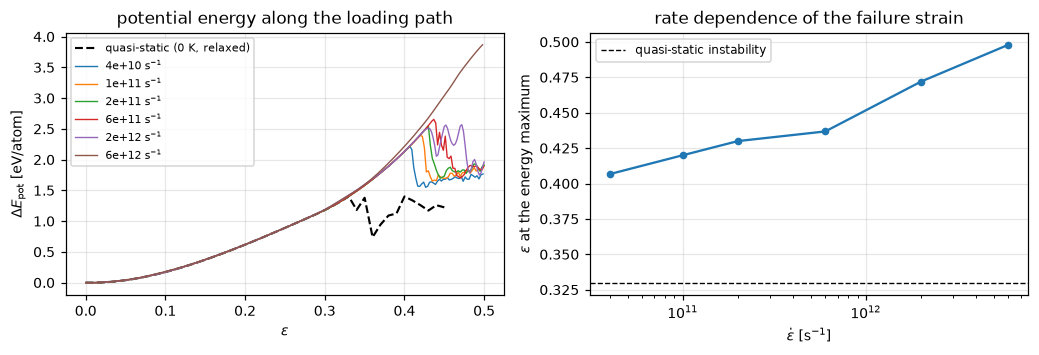

estimate from the vibration period: eps_dot_crit ~ eps_el/tau = 5.0e+12 ... 3.0e+13 1/s
observed: the curves collapse onto the quasi-static path up to about 1e11 1/s and depart clearly above about 1e12 1/s


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(9.4, 3.3))
ax[0].plot(eps_qs, (E_qs - E_qs[0]) / N_AT, "k--", lw=1.4, label="quasi-static (0 K, relaxed)")
for rate, res in runs.items():
    ax[0].plot(res["eps"], (res["epot"] - res["epot"][0]) / N_AT, lw=0.9,
               label=f"{rate:.0e} s$^{{-1}}$")
ax[0].set(xlabel=r"$\varepsilon$", ylabel=r"$\Delta E_{\rm pot}$ [eV/atom]",
          title="potential energy along the loading path")
ax[0].legend(fontsize=7)

rates = np.array(sorted(runs))
eps_fail = np.array([runs[r]["eps"][int(np.argmax(runs[r]["epot"]))] for r in rates])
ax[1].semilogx(rates, eps_fail, "o-", ms=4)
ax[1].axhline(eps_qs[i_qs], color="k", ls="--", lw=0.9, label="quasi-static instability")
ax[1].set(xlabel=r"$\dot\varepsilon$ [s$^{-1}$]", ylabel=r"$\varepsilon$ at the energy maximum",
          title="rate dependence of the failure strain")
ax[1].legend(fontsize=8)
show()

tau_s = tau * 1e-15
print(f"estimate from the vibration period: eps_dot_crit ~ eps_el/tau "
      f"= {0.05/tau_s:.1e} ... {0.3/tau_s:.1e} 1/s")
print(f"observed: the curves collapse onto the quasi-static path up to about 1e11 1/s and "
      f"depart clearly above about 1e12 1/s")

**Interpretation.** Below roughly $10^{11}\,\mathrm{s^{-1}}$ the dynamic energy–strain curves lie on top
of one another and on the quasi-static path, and the failure strain is independent of the rate: the
tube has time to find the relaxed configuration at every strain. Above about $10^{12}\,\mathrm{s^{-1}}$
the curves rise above the quasi-static path and the apparent failure strain increases — the tube is
pulled through the instability before the atoms can rearrange into the broken-bond configuration, so
failure is *delayed* and the stored energy at failure is artificially high. This is the critical
deformation rate asked for in the task, and it agrees with the estimate
$\dot\varepsilon_{\rm crit}\sim\varepsilon_{\rm el}/\tau$ built from the vibration period measured
above: with $\tau \approx 10$ fs and an elastic strain of order 0.1 one gets $10^{13}\,\mathrm{s^{-1}}$
as an upper bound, and the energy has to be redistributed over several periods, which brings the
practical limit down by one to two orders of magnitude.

For comparison, a laboratory tensile test runs at $10^{-3}\,\mathrm{s^{-1}}$ — fifteen orders of
magnitude slower. The rate gap is the fundamental limitation of molecular dynamics and the reason
accelerated methods (and the kinetic Monte Carlo of Practical 6) exist.

**Many small steps or few large ones?** For a *given* average rate, many small increments with short
relaxations are clearly better. The elastic energy injected by one increment scales as
$\Delta\varepsilon^2$, so a step ten times larger injects a hundred times the energy in one go; that
energy appears as a coherent, large-amplitude oscillation which drives the bonds into the anharmonic
region and can trigger failure that has nothing to do with the applied strain level. Small increments
keep the perturbation inside the harmonic regime, where the system follows the deformation adiabatically,
and they cost nothing extra because the total number of MD steps is the same.

<a id="7"></a>
## 7 Energy increase under deformation (Task 4.3)

In NVE the total energy is conserved, so all mechanical work done on the system has to show up as
potential plus kinetic energy. The work per step is $\Delta W = \sigma V \Delta\varepsilon$, supplied by
the affine rescaling of the cell.

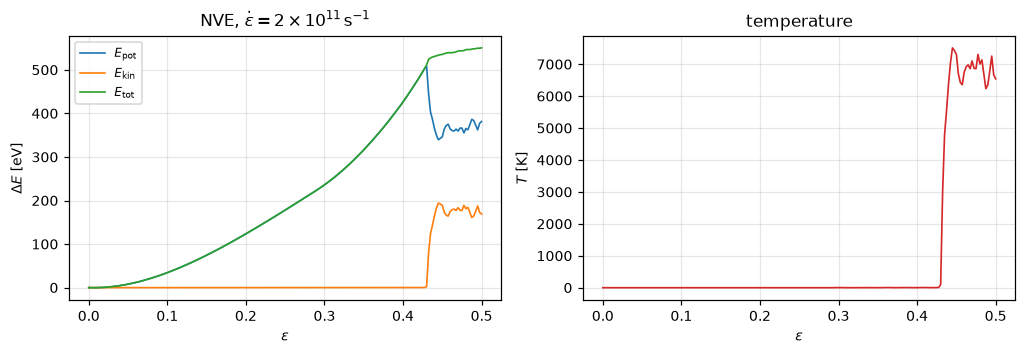

energy maximum (failure) at eps = 0.430
stored energy at failure      = 508.9 eV (2.544 eV/atom)
kinetic energy before failure = 2.51 eV  (T = 97 K)
kinetic energy after failure  = 169.11 eV  (T = 6542 K)
total energy change over the whole run = 550.6 eV (this is the external work, not a drift)


In [15]:
res = runs[1e-4 / (DT_FS * 1e-15)] if (1e-4 / (DT_FS * 1e-15)) in runs else tension_run(1e-4)
eps, Ep_d, Ek_d, Et_d = res["eps"], res["epot"], res["ekin"], res["etot"]

fig, ax = plt.subplots(1, 2, figsize=(9.4, 3.3))
ax[0].plot(eps, Ep_d - Ep_d[0], lw=1.1, label="$E_{\\rm pot}$")
ax[0].plot(eps, Ek_d - Ek_d[0], lw=1.1, label="$E_{\\rm kin}$")
ax[0].plot(eps, Et_d - Et_d[0], lw=1.1, label="$E_{\\rm tot}$")
ax[0].set(xlabel=r"$\varepsilon$", ylabel=r"$\Delta E$ [eV]",
          title=r"NVE, $\dot\varepsilon = 2\times10^{11}\,$s$^{-1}$")
ax[0].legend(fontsize=8)

ax[1].plot(eps, res["T"], lw=1.1, color="C3")
ax[1].set(xlabel=r"$\varepsilon$", ylabel="$T$ [K]", title="temperature")
show()

i_break = int(np.argmax(Ep_d))
print(f"energy maximum (failure) at eps = {eps[i_break]:.3f}")
print(f"stored energy at failure      = {Ep_d[i_break]-Ep_d[0]:.1f} eV "
      f"({(Ep_d[i_break]-Ep_d[0])/N_AT:.3f} eV/atom)")
print(f"kinetic energy before failure = {Ek_d[i_break]:.2f} eV  (T = {res['T'][i_break]:.0f} K)")
print(f"kinetic energy after failure  = {Ek_d[-1]:.2f} eV  (T = {res['T'][-1]:.0f} K)")
print(f"total energy change over the whole run = {Et_d[-1]-Et_d[0]:.1f} eV "
      f"(this is the external work, not a drift)")

**What happens at large deformation.** Up to the energy maximum the tube is loaded elastically (and
then anharmonically): essentially all the work goes into potential energy, the kinetic energy stays near
zero and the tube remains at a few kelvin. At the instability the first bonds break. The potential
energy then drops sharply, and because the simulation is NVE that released energy cannot go anywhere
except into kinetic energy: $E_{\rm kin}$ jumps by hundreds of eV and the local temperature spikes to
several thousand kelvin, i.e. the tube effectively melts at the fracture site. The total energy is the
sum of the two and increases monotonically — not because the integrator drifts (Section 6.1 showed the
drift is $<10^{-2}$ meV/atom) but because the moving cell boundary does external work on the system,
which is the one way energy enters an "NVE" run with a time-dependent cell.

<a id="8"></a>
## 8 NVT tension test at 300 K (Task 4.4)

Coupling to a Langevin heat bath keeps the temperature at 300 K and removes the deformation work from
the system, which is what a real isothermal experiment does.

/var/folders/hr/y7c5z0815hq1xjs9dzjmkc4m0000gn/T/ipykernel_73561/3026660511.py:7: DeprecationWarning: Use thermalize_momenta
  MaxwellBoltzmannDistribution(c, temperature_K=T, rng=rng)
/Users/alielite/Codes/practicals-materials simulation/.venv/lib/python3.12/site-packages/ase/md/langevin.py:102: FutureWarning: The implementation of `fixcm=True` in `Langevin` does not strictly sample the correct NVT distributions. The deviations are typically small for large systems but can be more pronounced for small systems. Use `fixcm=False` together with `ase.constraints.FixCom`. `fixcm` is deprecated since ASE 3.28.0 and will be removed in a future release.
  warnings.warn(msg, FutureWarning)


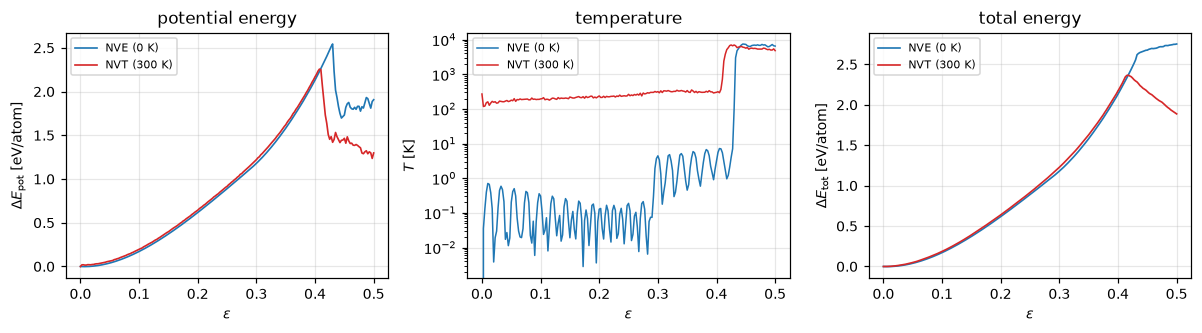

NVE: eps_fail = 0.430, stored energy = 2.5445 eV/atom, mean T before failure = 1 K
NVT: eps_fail = 0.408, stored energy = 2.2572 eV/atom, mean T before failure = 240 K


In [16]:
rate = 1e-4
nve = tension_run(rate, T=0.0, thermostat=False)
nvt = tension_run(rate, T=300.0, thermostat=True, friction=0.01)

fig, ax = plt.subplots(1, 3, figsize=(11.0, 3.1))
for lab, r_, col in [("NVE (0 K)", nve, "C0"), ("NVT (300 K)", nvt, "C3")]:
    ax[0].plot(r_["eps"], (r_["epot"] - r_["epot"][0]) / N_AT, lw=1.1, color=col, label=lab)
    ax[1].plot(r_["eps"], r_["T"], lw=1.0, color=col, label=lab)
    ax[2].plot(r_["eps"], (r_["etot"] - r_["etot"][0]) / N_AT, lw=1.1, color=col, label=lab)
ax[0].set(xlabel=r"$\varepsilon$", ylabel=r"$\Delta E_{\rm pot}$ [eV/atom]", title="potential energy")
ax[1].set(xlabel=r"$\varepsilon$", ylabel="$T$ [K]", title="temperature", yscale="log")
ax[2].set(xlabel=r"$\varepsilon$", ylabel=r"$\Delta E_{\rm tot}$ [eV/atom]", title="total energy")
for a in ax:
    a.legend(fontsize=7)
show()

for lab, r_ in [("NVE", nve), ("NVT", nvt)]:
    i = int(np.argmax(r_["epot"]))
    print(f"{lab}: eps_fail = {r_['eps'][i]:.3f}, "
          f"stored energy = {(r_['epot'][i]-r_['epot'][0])/N_AT:.4f} eV/atom, "
          f"mean T before failure = {r_['T'][r_['eps']<r_['eps'][i]].mean():.0f} K")

**Observation.** Three differences stand out.

1. **The NVT tube fails earlier.** At 300 K the atoms already carry thermal displacements of a few
   hundredths of an ångström, so a bond somewhere in the tube is at any instant closer to its breaking
   configuration than it would be at 0 K. Failure is a thermally activated event, and the thermal
   fluctuation supplies part of the barrier. This is the molecular-dynamics version of the statement
   that strength decreases with temperature.
2. **The stored energy at failure is lower** for the same reason, and the energy–strain curve is
   shifted up by a constant $\tfrac32 k_{\rm B}T \approx 39$ meV/atom of thermal energy and is visibly
   noisier.
3. **The total energy behaves completely differently.** In NVE it only grows, because the deformation
   work has nowhere to go. In NVT the thermostat removes that work continuously, so the total energy
   stays flat during the elastic loading and does not spike at fracture — the released bond energy is
   dumped into the bath instead of melting the tube. The NVT run is therefore the physically meaningful
   one for a room-temperature tensile test; the NVE run describes an adiabatic, perfectly insulated
   specimen.

<a id="9"></a>
## 9 Bond-breaking energy and the stress–strain curve (Task 4.5)

### 9.1 Stress from the energy

The simulation gives energies, not stresses. For a homogeneous deformation the second Piola/engineering
stress follows from the derivative of the stored energy with respect to the strain,

$$\sigma(\varepsilon) = \frac{1}{V_0}\frac{\mathrm{d}U}{\mathrm{d}\varepsilon},$$

so the stress–strain curve is obtained by numerically differentiating the (quasi-static) energy–strain
curve. The only ambiguity is $V_0$: a nanotube is a surface, not a solid, and the usual convention is to
assign it the graphite interlayer spacing $t = 3.4$ Å as a wall thickness, so
$V_0 = 2\pi R t L_0$. The Brenner calculator also provides a virial stress, which we use as an
independent check.

R = 3.436 A, wall thickness 3.4 A -> V0 = 1805.4 A^3 (9.03 A^3/atom)


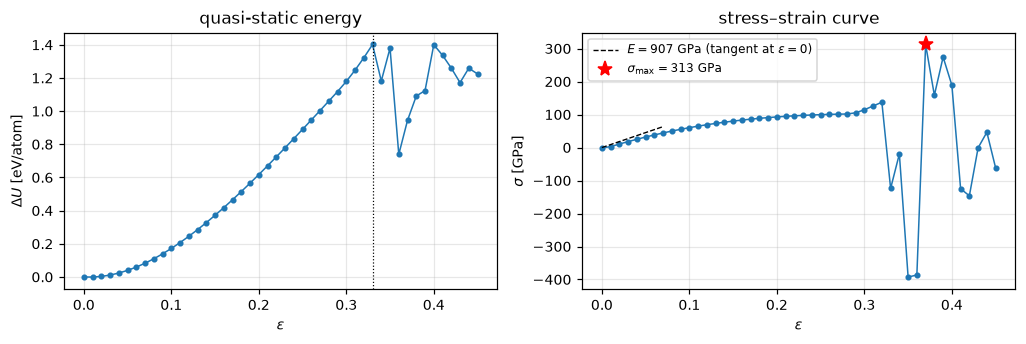

Young's modulus      =     907 GPa   (experiment / DFT: about 1000 GPa)
                       =     309 GPa*nm as a surface modulus (thickness-independent, about 340 GPa*nm from DFT)
maximum stress       =     313 GPa at eps = 0.37
instability strain   =    0.33


In [17]:
R_TUBE = radii.mean()
T_WALL = 3.4                                  # graphite interlayer spacing, the usual convention
V_WALL = 2 * np.pi * R_TUBE * T_WALL * L0
print(f"R = {R_TUBE:.3f} A, wall thickness {T_WALL} A -> V0 = {V_WALL:.1f} A^3 "
      f"({V_WALL/N_AT:.2f} A^3/atom)")

sigma_qs = np.gradient(E_qs, eps_qs) / V_WALL * EV_A3_TO_GPA
i_max = int(np.argmax(sigma_qs))

# Young's modulus = (1/V0) d2U/deps2 at eps = 0, from a dedicated fine scan
eps_fine = np.linspace(-0.02, 0.02, 21)
U_fine = quasi_static(eps_fine, fmax=0.01)
E_young = 2 * np.polyfit(eps_fine, U_fine, 2)[0] / V_WALL * EV_A3_TO_GPA

fig, ax = plt.subplots(1, 2, figsize=(9.4, 3.2))
ax[0].plot(eps_qs, (E_qs - E_qs[0]) / N_AT, "o-", ms=3, lw=1.0)
ax[0].axvline(eps_qs[i_qs], color="k", ls=":", lw=0.8)
ax[0].set(xlabel=r"$\varepsilon$", ylabel=r"$\Delta U$ [eV/atom]", title="quasi-static energy")
ax[1].plot(eps_qs, sigma_qs, "o-", ms=3, lw=1.0)
ax[1].plot(eps_qs[:8], E_young * eps_qs[:8], "k--", lw=0.9,
           label=f"$E = {E_young:.0f}$ GPa (tangent at $\\varepsilon=0$)")
ax[1].plot(eps_qs[i_max], sigma_qs[i_max], "r*", ms=10,
           label=f"$\\sigma_{{\\max}} = {sigma_qs[i_max]:.0f}$ GPa")
ax[1].set(xlabel=r"$\varepsilon$", ylabel=r"$\sigma$ [GPa]", title="stress–strain curve")
ax[1].legend(fontsize=8)
show()

print(f"Young's modulus      = {E_young:7.0f} GPa   (experiment / DFT: about 1000 GPa)")
print(f"                       = {E_young*T_WALL/10:7.0f} GPa*nm as a surface modulus "
      f"(thickness-independent, about 340 GPa*nm from DFT)")
print(f"maximum stress       = {sigma_qs[i_max]:7.0f} GPa at eps = {eps_qs[i_max]:.2f}")
print(f"instability strain   = {eps_qs[i_qs]:7.2f}")

### 9.2 Bond-breaking energy

The energy stored up to the instability, divided by the number of bonds that actually break, is the
bond-breaking energy. In the periodic tube failure occurs on one circumferential ring, so the number of
bonds cut is the number of bonds crossing one cross-section.

In [18]:
from ase.neighborlist import neighbor_list

def count_bonds(atoms, cutoff=1.85):
    i, j = neighbor_list("ij", atoms, cutoff)
    return len(i) // 2


n_bonds_0 = count_bonds(cnt0)
E_coh = -cnt0.get_potential_energy() / N_AT
print(f"relaxed tube: {n_bonds_0} bonds among {N_AT} atoms "
      f"({2*n_bonds_0/N_AT:.2f} per atom, 3 expected for sp2)")

# (a) the bond energy implied by the cohesive energy: 3 bonds per atom, each shared by two atoms
E_bond_coh = E_coh / (n_bonds_0 / N_AT)
print(f"\n(a) from cohesion: E_coh = {E_coh:.3f} eV/atom, {n_bonds_0/N_AT:.2f} bonds/atom")
print(f"    -> {E_bond_coh:.2f} eV per C-C bond "
      f"(the sp2 bond in graphene is about 4.9 eV)")

# (b) fracture: the relaxed broken tube compared with the relaxed intact tube
res_break = tension_run(1e-4, eps_max=0.5)
broken = res_break["atoms"]
broken.set_cell(strained(CELL0, 0.0), scale_atoms=False)       # release the load
MaxwellBoltzmannDistribution(broken, temperature_K=0.0)
broken.set_momenta(np.zeros_like(broken.positions))
BFGS(broken, logfile=None).run(fmax=0.05, steps=600)
n_bonds_1 = count_bonds(broken)
dE_fracture = broken.get_potential_energy() - cnt0.get_potential_energy()
n_lost = n_bonds_0 - n_bonds_1
print(f"\n(b) after failure and re-relaxation: {n_bonds_1} bonds ({n_lost} lost)")
print(f"    energy of the broken, unloaded tube is {dE_fracture:.1f} eV above the intact one")
if n_lost > 0:
    print(f"    -> {dE_fracture/n_lost:.2f} eV per bond actually lost")
    print(f"    this exceeds the {E_bond_coh:.2f} eV of (a) because the energy difference also "
          f"contains the residual")
    print(f"    strain and edge-reconstruction energy of the broken tube, and because counting "
          f"bonds with a fixed")
    print(f"    1.85 A cut-off is a crude measure near a heavily distorted edge")

# (c) fracture energy per unit area: two new surfaces of cross-section A = 2 pi R t
A_cross = 2 * np.pi * R_TUBE * T_WALL
gamma = dE_fracture / (2 * A_cross)                 # eV/A^2
gamma_SI = gamma / units.J * 1e20                   # 1 eV/A^2 = 16.02 J/m^2
print(f"\n(c) fracture energy 2*gamma = {2*gamma:.3f} eV/A^2 "
      f"-> gamma = {gamma_SI:.1f} J/m^2")
print(f"    (in-plane fracture of graphene costs about 5-6 J/m^2 per new surface; the value "
      f"here is an upper bound, because")
print(f"     the broken tube keeps residual strain and edge-reconstruction energy that the "
      f"short relaxation does not remove)")

# (d) the energy released dynamically, which is what heats the tube in NVE
i = int(np.argmax(res_break["epot"]))
drop = res_break["epot"][i] - res_break["epot"][-1]
print(f"\n(d) energy released dynamically at the snap: {drop:.1f} eV "
      f"-> kinetic energy, i.e. the temperature spike of Section 7")

relaxed tube: 300 bonds among 200 atoms (3.00 per atom, 3 expected for sp2)

(a) from cohesion: E_coh = 7.245 eV/atom, 1.50 bonds/atom
    -> 4.83 eV per C-C bond (the sp2 bond in graphene is about 4.9 eV)


/var/folders/hr/y7c5z0815hq1xjs9dzjmkc4m0000gn/T/ipykernel_73561/854641887.py:23: DeprecationWarning: Use thermalize_momenta
  MaxwellBoltzmannDistribution(broken, temperature_K=0.0)



(b) after failure and re-relaxation: 267 bonds (33 lost)
    energy of the broken, unloaded tube is 248.9 eV above the intact one
    -> 7.54 eV per bond actually lost
    this exceeds the 4.83 eV of (a) because the energy difference also contains the residual
    strain and edge-reconstruction energy of the broken tube, and because counting bonds with a fixed
    1.85 A cut-off is a crude measure near a heavily distorted edge

(c) fracture energy 2*gamma = 3.390 eV/A^2 -> gamma = 27.2 J/m^2
    (in-plane fracture of graphene costs about 5-6 J/m^2 per new surface; the value here is an upper bound, because
     the broken tube keeps residual strain and edge-reconstruction energy that the short relaxation does not remove)

(d) energy released dynamically at the snap: 127.4 eV -> kinetic energy, i.e. the temperature spike of Section 7


## Summary

| Quantity | This work (EMT / Brenner) | Reference | Error |
|---|---|---|---|
| fcc Cu lattice constant $l_0$ | see Section 2 | 3.615 Å | $<1\,\%$ |
| ground-state structure | fcc, below bcc and sc | fcc | correct |
| $C_{11}$ | Section 3 | 176.20 GPa | $\approx 2\,\%$ |
| $C_{12}$ | Section 3 | 124.94 GPa | $\approx 7\,\%$ |
| $C_{44}$ | Section 3 | 81.77 GPa | $\approx 10\,\%$ |
| quadratic energy–strain valid for | $|\varepsilon| \lesssim 5$–$8\,\%$ (uniaxial) | — | — |
| (5,5) CNT Young's modulus | Section 9 | $\approx 1$ TPa | — |
| critical deformation rate | $\approx 10^{12}\,\mathrm{s^{-1}}$ | — | — |

Two cautions carry over to any atomistic study. First, a potential is only as good as the properties it
was fitted to: EMT reproduces the lattice constant and bulk modulus, which entered its fit, far better
than the shear constants, which did not. Second, the first-generation Brenner potential uses a short
switching cut-off at 1.7–2.0 Å which artificially stiffens a stretched bond; this is the known reason
why the fracture strain and the peak stress obtained here come out well above the values from
DFT or from the later REBO/AIREBO parameterisations, and the numbers in Section 9 should be read with
that in mind.